# Part 2 — Installing Ollama

## Exercise 1 — Verify the environment

In [1]:
import sys, platform
print("Python  :", sys.version)
print("System  :", platform.system(), platform.release())
assert sys.version_info >= (3, 10), "Python 3.10+ required"

Python  : 3.15.1 (tags/v3.15.1:c37e74c, Oct 21 2026, 06:24:08) [MSC v.1951 64 bit (AMD64)]
System  : Windows 10


In [2]:
!pip --version

pip 26.2.2 from C:\Users\MOUADILI\venv_ollama\Lib\site-packages\pip (python 3.15)



## Exercise 2 — Install Ollama 

In [3]:
!ollama --version

ollama version is 0.40.11


In [4]:
import requests

OLLAMA = "http://localhost:11434"

try:
    r = requests.get(OLLAMA, timeout=3)
    print("✅ Ollama server reachable:", r.text)
except requests.exceptions.ConnectionError:
    print("❌ Ollama is not running. Start it with `ollama serve` in a terminal.")

✅ Ollama server reachable: Ollama is running


# Part 3 — Your First Local LLM

## Exercise 3 — Download a model

In [5]:
# Models used throughout the lab — edit if needed
MODEL  = "qwen3.5"   # Model 1
MODEL2 = "gemma3"    # Model 2 (used in the comparison parts)

In [6]:
!ollama pull {MODEL}

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest 
pulling f836f08f9211:   0% ▕                  ▏ 937 KB/921 MB                  pulling manifest 
pulling f836f08f9211:   0% ▕                  ▏ 1.6 MB/921 MB                  pulling manifest 
pulling f836f08f9211:   0% ▕                  ▏ 1.8 MB/921 MB                  pulling manifest 
pulling f836f08f9211:   0% ▕                  ▏ 3.5 MB/921 MB                  pulling manifest 
pulli

In [7]:
!ollama list

NAME              ID              SIZE      MODIFIED       
qwen3.5:latest    56671c2ab938    6.6 GB    46 seconds ago    
qwen2.5vl:3b      fb90415cde1e    3.2 GB    2 days ago        


## Exercise 4 — Run the model

In [11]:
import time, json

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    """Call Ollama /api/generate (non-streaming) and return the full JSON dict
    plus the measured wall-clock time under the key 'wall_s'."""
    payload = {"model": model or MODEL, "prompt": prompt, "stream": False}
    if system:  payload["system"] = system
    if fmt:     payload["format"] = fmt          # "json" or a JSON schema
    if images:  payload["images"] = images       # list of base64 strings
    if options: payload["options"] = options
    if think is not None: payload["think"] = think  # False disables 'thinking' on reasoning models
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=1800)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    """Shortcut: return only the text, and print timing."""
    out = generate(prompt, **kw)
    print(f"[{out['wall_s']:.1f}s]")
    return out["response"]

In [9]:
for p in [
    "Explain what artificial intelligence is in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("="*80, "\nPROMPT:", p, "\n")
    print(ask(p))

PROMPT: Explain what artificial intelligence is in five sentences. 

[274.0s]
Artificial intelligence refers to computer systems designed to mimic human cognitive functions like learning and reasoning. These technologies process vast amounts of data to perform tasks that typically require human intelligence, such as recognizing speech or making decisions. Through machine learning algorithms, AI models improve their performance by analyzing patterns rather than relying solely on pre-programmed rules. From virtual assistants to autonomous vehicles, AI applications are increasingly integrated into daily life to enhance efficiency and productivity. Ultimately, the goal of this technology is to augment human capabilities while automating complex tasks across various industries.
PROMPT: Explain artificial intelligence to a 10-year-old child. 

[350.6s]
Imagine you have a robot friend who wants to play catch with you. If you show it how to throw a ball, it might try to copy you at first, but 

### ✍️ Exercise 4 — Answers

**1. Did the model produce different answers? Why?**

Yes. Although the topic is the same, each prompt specifies a different audience and format, and the model adapted its output accordingly. For the first prompt, it gave a concise, general definition that respected the constraint of exactly five sentences. For the 10-year-old child, it used simple vocabulary and concrete analogies (a robot friend playing catch, learning to ride a bike, recognizing cats from pictures), familiar examples (Siri, video games, Netflix recommendations) and a reassuring tone. For the computer science professor, it produced a peer-level, technical answer covering symbolic vs. statistical AI (GOFAI), optimization (SGD, non-convex loss landscapes), inductive bias, scaling laws, emergence and interpretability.

The length and complexity of the answer grew with the expertise of the target audience. This shows that the prompt conditions the generated text: the LLM predicts the most likely continuation given the instructions it receives. Generation is also stochastic (sampling with a temperature greater than 0), so the same prompt run twice would not produce exactly the same text.

It is also worth noting that the professor-level answer sounds authoritative but contains some inaccuracies (for example, implicit regularization is usually associated with small batches, not large ones). This illustrates that a fluent answer from a mid-size model must still be checked critically.

**2. Is the model communicating with a cloud API?**

No. The requests are sent to http://localhost:11434/api/generate. Localhost (127.0.0.1) refers to my own machine, so the HTTP request never leaves the computer. No API key or account is required, and no data is sent to any external provider. The Windows Task Manager confirms this: the network activity of the inference process stays at 0 Mbit/s.

**3. Where is inference being performed?**

Locally, on my computer's CPU. The Ollama server loads the model weights (qwen3.5, 9B parameters, 6.6 GB on disk) into RAM. The Windows Task Manager shows the llama-server process (Ollama's inference engine, based on llama.cpp) holding about 5 GB of RAM, with total memory usage reaching 91%.

The measured response times were 274.0 s, 350.6 s and 584.6 s, about 20 minutes in total. Two factors explain these values. First, response time increases with the length of the generated answer: the professor-level answer is the longest and took the most time. Second, Qwen 3.5 is a reasoning model: by default it generates internal "thinking" tokens before the final answer, which adds computation.

These times are much slower than a cloud API, which typically answers in a few seconds. This illustrates the main trade-off of local AI: running a 9B model on a CPU without a dedicated GPU, with limited RAM, works but is slow.

**4. What happens if the Internet connection is disabled?**

After disabling Wi-Fi and re-running a prompt, the model [still answered normally]. Once the model has been downloaded with ollama pull, Internet access is only needed to download new models or updates; inference itself is fully offline. This confirms the privacy and offline-operation advantages discussed in Part 1.

# Part 4 — Experiment with Prompts

## Exercise 5 — Prompt engineering

In [12]:
prompt_a = """You are a university professor.

Explain the concept of a Directed Acyclic Graph (DAG).

Your answer must contain:
1. Definition
2. Example
3. Adjacency matrix
4. Real-world application
5. One Python example"""

print(ask(prompt_a))

[824.5s]
Good morning, class! Please take your seats. Today we are diving into one of the most fundamental structures in graph theory and computer science: the **Directed Acyclic Graph**, or DAG for short. This structure appears frequently in algorithms, systems design, and everyday problem-solving.

Here is the breakdown you requested for today's lecture.

### 1. Definition
A **Directed Acyclic Graph (DAG)** is a type of graph that possesses two specific properties:
1.  **Directed:** The edges have a direction. Each edge connects one node (source) to another distinct node (target), typically represented as an arrow $u \to v$. This implies order; the process must happen in a specific sequence.
2.  **Acyclic:** There are no cycles within the graph. It is impossible to start at any node and traverse a series of directed edges that eventually lead back to the starting node. If you follow the arrows, they can only move forward (in terms of topological order) and never loop back on themselv

In [13]:
prompt_b = """You are a university professor.

Explain DAGs to a first-year computer science student.

Use simple language and one concrete example."""

print(ask(prompt_b))

[921.5s]
Hello everyone! Please take your seats and relax. If you are here for Data Structures, welcome to the journey of understanding how computers organize work.

Today, we are talking about **DAGs**. That stands for **Directed Acyclic Graph**. It sounds scary with all the technical words, so let’s strip that away.

### What is a DAG?
Imagine a map where the locations aren't just dots on a flat line, but they have rules about which way you can travel. A DAG breaks down into three simple parts:

1.  **Graph:** Think of a box of LEGOs or a network of roads. You have **nodes** (dots/boxes representing tasks or items) and **edges** (lines/arrows connecting them).
2.  **Directed:** The arrows only go **one way**. If I draw an arrow from A to B, it means "A must happen before B." You cannot go backward. Time moves forward only.
3.  **Acyclic:** This is the most important part. "Cyclic" means circular or a loop (like A goes to B, B goes back to A). An **acyclic** graph simply means there a

**Compare the two answers. Explain the role of: role · context · constraints · output format · specificity.**

The two prompts share the same role and topic, but they led to very different answers. Prompt A produced a structured and technical lecture with a formal definition, an example, an adjacency matrix, real-world applications and Python code. Prompt B produced a shorter, more accessible explanation built around everyday analogies and a single example, with no notation, matrix or code.

Role: it sets the tone and the level of expertise. Since both prompts used the same role, it explains the shared teaching style rather than the differences.

Context: specifying the audience (a first-year student in prompt B) made the model simplify its vocabulary and explain each term step by step. Without this information, prompt A received a more academic answer.

Constraints: they guide what the model must or must not include. Prompt B's requirements (simple language, one example) were respected, while prompt A's mandatory elements forced the model to add technical content such as the matrix and the code.

Output format: the numbered list in prompt A worked like a template, and the answer followed the same five sections in the same order. Prompt B left the structure open, which gave the model more freedom but less control.

Specificity: the more precise the prompt, the closer the answer is to what the user expects, and the easier it is to check. However, both answers contained small logical inconsistencies in their examples, which shows that a detailed prompt improves structure but does not guarantee accuracy.

Performance: the answers took about 14 and 15 minutes. Prompt B was slower even though its output was shorter, which suggests that the model's internal reasoning and the high memory load affect response time as much as output length.

# Part 5 — Model Management

## Exercise 6 — List, show, and monitor models

In [14]:
!ollama list

NAME              ID              SIZE      MODIFIED          
qwen3.5:latest    56671c2ab938    6.6 GB    About an hour ago    
qwen2.5vl:3b      fb90415cde1e    3.2 GB    2 days ago           


In [15]:
!ollama show {MODEL}

  Model
    architecture        qwen35             
    parameters          9.0B               
    context length      262144             
    embedding length    4096               
    quantization        Q4_K_M             
    requires            0.30.0             
    renderer            qwen3.5            
    parser              qwen3.5            
    template source     renderer_parser    

  Capabilities
    completion     
    vision         
    tools          
    thinking       
        levels     false, true    
        default    true           

  Projector
    architecture        clip       
    parameters          456.01M    
    embedding length    1152       
    dimensions          4096       

  Parameters
    temperature         1       
    top_k               20      
    top_p               0.95    
    presence_penalty    1.5     

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          



In [16]:
!ollama ps

NAME    ID    SIZE    PROCESSOR    CONTEXT    RUNNER    UNTIL 


In [18]:
%pip install pandas

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/10.9 MB 11.5 MB/s eta 0:00:01
   --------------- ------------------------ 4.2/10.9 MB 12.6 MB/s eta 0:00:01
   ------------------------ --------------- 6.6/10.9 MB 12.1 MB/s eta 0:00:01
   ------------------------------- -------- 8.7/10.9 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------  10.7/10.9 MB 11.6 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 11.0 MB/s  0:00:01
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ------ --------------------------------- 2.1/12.7 MB 10.8 MB/s eta 0:00:01
   -------------- ------------------------- 4.5/12.7 MB 10.8 MB/s eta 0:00:01
   --------------------- ------------------ 6.8/12.7 MB 11.1 MB/s eta 0:00:01
   ---------------------------- ----------- 9.2/12.7 MB 11.1 MB/s eta 0:00:01
   ----------------------------------- ---- 11.3/12.7 MB 11.1 MB/s eta 0:00:01
  

In [19]:
import pandas as pd

def downloaded_models():
    tags = requests.get(f"{OLLAMA}/api/tags").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "family": m["details"].get("family"),
        "params": m["details"].get("parameter_size"),
        "quantization": m["details"].get("quantization_level"),
    } for m in tags])

def loaded_models():
    ps = requests.get(f"{OLLAMA}/api/ps").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "in_VRAM_GB": round(m.get("size_vram", 0)/1e9, 2),
        "expires_at": m.get("expires_at"),
    } for m in ps])

print("Downloaded:"); display(downloaded_models())
print("Currently loaded in memory:"); display(loaded_models())

Downloaded:


,name,size_GB,family,params,quantization
0,qwen3.5:latest,6.55,qwen35,9.0B,Q4_K_M
1,qwen2.5vl:3b,3.20,qwen25vl,3.8B,Q4_K_M


Currently loaded in memory:


""


**What information do you get from ollama list vs ollama ps?**

ollama list shows all the models stored on the disk, with their name, ID, size and download date. Here it lists qwen3.5 (6.6 GB) and qwen2.5vl:3b (3.2 GB). ollama ps shows only the models currently loaded in memory, with the memory used, the processor (CPU or GPU), the context size and the time before unloading. In my case, the ps table was empty because the model had been inactive for more than 5 minutes.

**What is the difference between a model that is downloaded and one that is loaded?**

A downloaded model is a file saved on the disk: it takes storage space but uses no RAM or CPU. A loaded model has its weights copied into RAM (or GPU memory) and is ready to answer immediately. Ollama loads a model automatically on the first request, which explains why the first call is slower, and unloads it after about 5 minutes of inactivity to free memory.

# Part 6 — Compare Two Local Models

In [20]:
!ollama pull {MODEL2}
!ollama list

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest 
pulling f06e91e18fc7:   0% ▕                  ▏ 198 KB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% ▕                  ▏ 1.3 MB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% ▕                  ▏ 2.8 MB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% ▕                  ▏ 3.6 MB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% ▕                  ▏ 5.9 MB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% ▕                  ▏ 6.4 MB/2.5 GB                  pulling manifest 
p

NAME              ID              SIZE      MODIFIED               
gemma3:latest     68ceab7e468a    3.4 GB    Less than a second ago    
qwen3.5:latest    56671c2ab938    6.6 GB    2 hours ago               
qwen2.5vl:3b      fb90415cde1e    3.2 GB    2 days ago                


## Exercise 7 — Same prompt, different models

In [21]:
prime_prompt = """Write a Python function that determines whether a number is prime.

Requirements:
- Python
- Type hints
- Docstring
- Explain the algorithm
- Give its time complexity"""

results = {}
for m in (MODEL, MODEL2):
    print("="*80, f"\nMODEL: {m}\n")
    out = generate(prime_prompt, model=m)
    results[m] = out
    print(out["response"])
    print(f"\n⏱ {out['wall_s']:.1f}s")

MODEL: qwen3.5

Here's a Python function that determines whether a given number is prime. It includes type hints, a docstring, and an explanation of the algorithm along with its time complexity.

```python
import math
from typing import Optional

def is_prime(n: int) -> bool:
    """
    Determines whether a given integer is a prime number.

    A prime number is a natural number greater than 1 that has no positive
    divisors other than 1 and itself.

    Parameters:
        n (int): The integer to check for primality.

    Returns:
        bool: True if the number is prime, False otherwise.

    Raises:
        ValueError: If the input is not an integer or is negative.

    Algorithm:
        1. Handle edge cases:
           - Numbers less than 2 are not prime.
           - 2 and 3 are prime.
           - Even numbers greater than 2 are not prime.
        2. For odd numbers, test divisibility from 3 up to √n in steps of 6.
           This is based on the fact that all primes > 3 are

In [22]:
scores = {
    MODEL:  {"Response quality /5": None, "Code correctness /5": None},
    MODEL2: {"Response quality /5": None, "Code correctness /5": None},
}  # <- replace None with your scores

table = pd.DataFrame([
    {"Model": m, "Response time (s)": round(results[m]["wall_s"], 1), **scores[m]}
    for m in (MODEL, MODEL2)
])
table

,Model,Response time (s),Response quality /5,Code correctness /5
0,qwen3.5,246.6,None,None
1,gemma3,190.0,None,None


In [23]:
def is_prime_reference(n: int) -> bool:
    if n < 2: return False
    if n < 4: return True
    if n % 2 == 0: return False
    i = 3
    while i * i <= n:
        if n % i == 0: return False
        i += 2
    return True

# Paste the model's function below as `candidate` and compare:
# candidate = is_prime
# assert all(candidate(n) == is_prime_reference(n) for n in range(-5, 2000)), "Incorrect!"
# print("✅ candidate matches the reference on 0..2000")

In [24]:
import math

# Function generated by qwen3.5
def is_prime_qwen(n: int) -> bool:
    if not isinstance(n, int):
        raise TypeError("Input must be an integer.")
    if n < 2:
        return False
    if n in (2, 3):
        return True
    if n % 2 == 0:
        return False
    limit = int(math.isqrt(n))
    for divisor in range(3, limit + 1, 2):
        if n % divisor == 0:
            return False
    return True

# Function generated by gemma3
def is_prime_gemma(number: int) -> bool:
    if number <= 1:
        return False
    for i in range(2, int(number**0.5) + 1):
        if number % i == 0:
            return False
    return True

# Comparison with the reference
for name, candidate in [("qwen3.5", is_prime_qwen), ("gemma3", is_prime_gemma)]:
    assert all(candidate(n) == is_prime_reference(n) for n in range(-5, 2000)), f"{name}: Incorrect!"
    print(f" {name} matches the reference on -5..2000")

 qwen3.5 matches the reference on -5..2000
 gemma3 matches the reference on -5..2000


**Which model is faster?**

Gemma 3 was faster: 190.0 s against 246.6 s for Qwen 3.5. It is a smaller model, and it does not spend time on a reasoning step before answering.

**Which produces better code?**

Both functions are correct: they give the same results as the reference on all numbers from -5 to 2000. The Qwen 3.5 code is slightly better because it skips even numbers, so it does fewer checks. However, its explanation does not always match its code.

**Which uses more memory?**

Qwen 3.5 uses more memory. It has 9 billion parameters and takes 6.6 GB on disk, while Gemma 3 has 4 billion parameters and takes about 3.3 GB. On my computer, Qwen 3.5 alone used about 5 GB of RAM.

**Which would you choose for programming assistance?**

On my computer, I would choose Gemma 3. It gives correct code, it answers faster and it needs less memory, which matters on a machine without a GPU. I would use Qwen 3.5 only when I need a more careful answer and can wait longer.

**Is the largest model necessarily the best?**

No. The larger model gave slightly better code, but it was slower, used more memory, and still made mistakes in its explanation. For a simple task like this one, a smaller model is good enough. The best choice depends on the task, the hardware and how fast we need the answer.

# Part 7 — Using Local AI from Python

## Exercise 8 — Python + Ollama

In [25]:
!pip install -q requests

In [27]:
import os
os.makedirs("local_ai_lab", exist_ok=True)

In [28]:

%%writefile local_ai_lab/app.py
import requests

url = "http://localhost:11434/api/generate"

data = {
    "model": "qwen3.5",
    "prompt": "Explain recursion in Python.",
    "stream": False
}

response = requests.post(url, json=data)
result = response.json()
print(result["response"])

Writing local_ai_lab/app.py


In [29]:
%%writefile local_ai_lab/requirements.txt
requests

Writing local_ai_lab/requirements.txt


In [30]:
%%writefile local_ai_lab/README.md
# local_ai_lab
Minimal Python client for a local Ollama server.
Run: `python app.py`

Writing local_ai_lab/README.md


In [31]:
!python local_ai_lab/app.py

Recursion in Python is a programming technique where a function calls itself to solve a problem by breaking it down into smaller, more manageable subproblems. It's particularly powerful for problems that can be expressed in terms of similar or reduced versions of themselves.

---

### 🔑 Core Concepts

Every recursive function must include:

1. **Base Case**: A condition that stops the recursion and prevents infinite loops.
2. **Recursive Case**: The step where the function calls itself with modified arguments to move toward the base case.

Without a proper base case, a recursive function will raise a `RecursionError`.

---

### 🧩 Basic Example: Factorial

```python
def factorial(n):
    if n == 0 or n == 1:           # Base case
        return 1
    else:                          # Recursive case
        return n * factorial(n - 1)
```

**Example:**
```python
print(factorial(5))  # Output: 120
```

---

### 📁 Recursive Function to Traverse Nested Lists

```python
def flatten(lst):
    

In [32]:
out = generate("Explain recursion in Python.")
print(out["response"][:600], "...\n")
print({k: v for k, v in out.items() if k not in ("response", "context", "thinking")})

# Recursion in Python

Recursion is a programming technique where a function calls itself directly or indirectly until a stopping condition is met. In Python, it's used to solve problems that exhibit repetitive or self-similar structures.

---

## 🔑 Key Components of Recursion

Every recursive function must include:

1. **Base Case**: The condition that stops further recursion (prevents infinite loops).
2. **Recursive Case**: The part where the function calls itself with modified arguments to move toward the base case.

---

## 📘 Basic Example: Factorial Function

```python
def factorial(n):
  ...

{'model': 'qwen3.5', 'created_at': '2026-10-26T01:50:53.0340635Z', 'done': True, 'done_reason': 'stop', 'total_duration': 307861643900, 'load_duration': 16983400, 'prompt_eval_count': 16, 'prompt_eval_cached_count': 12, 'prompt_eval_duration': 342300000, 'eval_count': 1118, 'eval_duration': 307440141000, 'wall_s': 309.9652913000009}


# Part 8 — Build a Local AI Chatbot

## Exercise 9 — Interactive chatbot

In [33]:
URL = f"{OLLAMA}/api/generate"

def ask_ai(prompt):
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    return response.json()["response"]

def chat_loop_stateless():
    print("Local AI Assistant\nType 'exit' to stop.")
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai(question))

# chat_loop_stateless()   # <- uncomment to run

In [35]:
# Non-interactive test (works without typing):
for q in ["What is machine learning?", "Explain reinforcement learning."]:
    print("You:", q); print("AI:", ask_ai(q)[:500], "...\n")

You: What is machine learning?
AI: **Machine learning (ML)** is a subset of artificial intelligence (AI) that gives computers the ability to learn from data without being explicitly programmed for specific tasks.

Instead of writing rigid rules to tell a computer exactly how to solve a problem, machine learning involves feeding the computer large amounts of **data**, allowing it to identify patterns and make decisions or predictions on its own.

### Key Concepts

*   **Learning:** The system improves its performance over time as  ...

You: Explain reinforcement learning.
AI: **Reinforcement Learning (RL)** is a type of machine learning where an agent learns to make decisions by interacting with an environment through trial and error.

Unlike other types of AI, RL does not rely on a labeled dataset (like "cat = dog"). Instead, it receives **rewards** or **punishments** based on its actions and learns the best strategy to maximize the total reward over time.

Here is a breakdown of how i

# Part 9 — Add Conversation Memory

In [36]:
history = []

def ask_ai_memory(question):
    history.append(f"User: {question}")
    prompt = "\n".join(history) + "\nAssistant:"
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    answer = response.json()["response"]
    history.append(f"Assistant: {answer}")
    return answer

def chat_loop_memory():
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai_memory(question))

# chat_loop_memory()   # <- uncomment for interactive use

In [37]:
history.clear()
for q in ["My name is Ahmed.", "What is my name?"]:
    print("You:", q)
    print("AI :", ask_ai_memory(q), "\n")

You: My name is Ahmed.
AI : Hello Ahmed! It’s nice to meet you. How can I assist you today? 

You: What is my name?
AI : Your name is Ahmed! Is there anything else I can help you with? 



In [38]:
print("What the model actually received on the last call:\n" + "-"*50)
print("\n".join(history[:-1]) + "\nAssistant:")

What the model actually received on the last call:
--------------------------------------------------
User: My name is Ahmed.
Assistant: Hello Ahmed! It’s nice to meet you. How can I assist you today?
User: What is my name?
Assistant:


**Why does the model remember the name? Is the LLM itself remembering?**

No, the LLM does not remember anything. It is stateless: each request is treated as a new conversation, as we saw in Part 8.

The memory comes from our Python code. The history list stores all questions and answers, and the whole list is sent as the prompt with each new request. So the model does not recall the name: it simply reads "My name is Ahmed" in the prompt it receives.

This has limits: the prompt grows with each message, which makes requests slower and can exceed the model's context length. The memory is also lost when the program stops or the list is cleared.

In [39]:
def chat(messages, model=None, **kw):
    payload = {"model": model or MODEL, "messages": messages, "stream": False, **kw}
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()

msgs = [{"role": "system", "content": "You are a concise assistant."},
        {"role": "user", "content": "My name is Ahmed."}]
reply = chat(msgs)["message"]
msgs.append(reply)
msgs.append({"role": "user", "content": "What is my name?"})
print(chat(msgs)["message"]["content"])

Your name is Ahmed.


# Part 10 — Local AI for Software Engineering

## Exercise 10 — Code assistant

In [41]:
java_review = """You are a senior Java developer.

Review the following Java code:

public class Calculator {

    public int divide(int a, int b) {
        return a / b;
    }
}

Identify:
1. Potential problems
2. Runtime errors
3. Improvements
4. Corrected code"""

print(ask(java_review))

[403.8s]
### Java Calculator Class Code Review

#### 1. Potential Problems
- ❌ Division by zero: No validation for `b == 0` → throws `ArithmeticException`.
- ❌ Unsafe integer division: Always truncates decimal parts; may lose precision.
- ❌ Missing documentation: No JavaDoc, purpose, or expected behavior descriptions.
- ❌ Lack of error handling: Does not throw informative exceptions for invalid input.
- ❌ Limited functionality: Supports only basic `int` arithmetic without flexibility.

#### 2. Runtime Errors
- ⚠️ **ArithmeticException**: Occurs if `b == 0`. Example:
  ```java
  int result = new Calculator().divide(10, 0); // throws ArithmeticException
  ```

#### 3. Suggested Improvements
- ✅ Add input validation for zero divisor.
- ✅ Use proper custom exceptions (e.g., `IllegalArgumentException`).
- ✅ Consider supporting floating point division via an overloaded method.
- ✅ Add JavaDoc documentation for class and methods.
- ✅ Include unit tests to verify edge cases.
- ✅ Encapsulate ca

In [42]:
buggy = """You are a senior Java developer.

Find the bug in this code and explain how to fix it:

public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        age = age;
    }

    public String getName() {
        return name;
    }
}"""

print(ask(buggy))

[206.5s]
# Bug Found in `setAge()` Method

## The Problem

In the `Student` class, the `setAge(int age)` method does not assign the passed parameter to the actual instance field (`age`). Instead, it assigns the local variable to itself:

```java
public void setAge(int age) {
    age = age;  // Bug! This does nothing
}
```

This effectively makes the setter a no-op. The instance variable `age` is never updated, meaning any call to this method has no effect on the object's state.

## Why This Happens

In Java, when you declare a field like:

```java
private int age;
```

It becomes a member variable unique to each object. When you pass `int age` into a method, it creates a local parameter with the same name as the field but completely separate in scope. To update the field from within an instance method, you must use `this.age = age;`.

## The Fix

Update the `setAge()` method to assign the parameter value to the field:

```java
public void setAge(int age) {
    this.age = age;  // Corre

**Expected finding: age = age; assigns the parameter to itself (variable shadowing); it should be this.age = age;. Did your model find it? Is age also never initialized in the constructor?**

Yes, the model found the bug. It explained that the parameter age hides the field with the same name, so age = age only assigns the parameter to itself and the field is never updated. It proposed the correct fix, this.age = age, and also noticed that the class has no getAge() method. However, part of its explanation is confusing: in the "alternative" sections, it repeats the wrong code and announces a renamed parameter that it never actually renames.

Yes, age is never initialized in the constructor, which only sets the name. This does not cause an error in Java, because an int field automatically receives the default value 0. But combined with the bug in setAge, the age of every student stays at 0 forever. The model did not point out this second issue. A better design would be to add age as a constructor parameter, or at least to check that the value given to setAge is valid (for example, not negative).

# Part 11 — Structured Output

## Exercise 11

In [43]:
json_prompt = """Analyze the following student:

Name: Ahmed
Age: 21
Grade: 15.5
Absences: 2

Return ONLY JSON with this structure:

{
  "name": "...",
  "age": 0,
  "grade": 0,
  "risk": "...",
  "recommendation": "..."
}"""

raw = ask(json_prompt, think=False)
print(raw)

[40.9s]
```json
{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "Low",
  "recommendation": "Continue current academic support with occasional check-ins to monitor engagement and well-being."
}
```


In [44]:
import re

def extract_json(text):
    """Robust parsing: strip ```json fences and grab the first {...} block."""
    text = re.sub(r"```(?:json)?", "", text).strip()
    m = re.search(r"\{.*\}", text, re.DOTALL)
    return json.loads(m.group(0))

try:
    print(extract_json(raw))
except Exception as e:
    print("❌ Could not parse:", e)

{'name': 'Ahmed', 'age': 21, 'grade': 15.5, 'risk': 'Low', 'recommendation': 'Continue current academic support with occasional check-ins to monitor engagement and well-being.'}


In [45]:
schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "age": {"type": "integer"},
        "grade": {"type": "number"},
        "risk": {"type": "string", "enum": ["low", "medium", "high"]},
        "recommendation": {"type": "string"},
    },
    "required": ["name", "age", "grade", "risk", "recommendation"],
}

out = generate(json_prompt, fmt=schema, think=False)
student = json.loads(out["response"])
print(json.dumps(student, indent=2))
print("Type of grade:", type(student["grade"]))

{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "low",
  "recommendation": "Continue current performance; consider encouraging leadership roles or peer mentoring to leverage strong academic standing."
}
Type of grade: <class 'float'>


**Why is structured output important when integrating an LLM into a software application?**

A program cannot read free text the way a human does: it needs data in a fixed, predictable format to process it automatically, for example to store it in a database, display it or use it in calculations.

The naive approach shows the problem. Even when asked for "ONLY JSON", the model wrapped its answer in markdown code fences, so json.loads would have failed without a cleaning step. The model can also change field names, add text, or use inconsistent values: here it returned "Low", while another run could return "low" or "Low risk".

With a JSON schema (the format parameter), Ollama forces the model to follow the structure exactly: all required fields are present, each value has the correct type (grade is a float, age an integer), and risk can only be "low", "medium" or "high". The output can then be parsed directly and used safely, without fragile cleaning code. Structured output therefore makes the LLM reliable enough to be a component of a real application.

# Part 12 — Local AI Document Assistant

In [47]:
os.makedirs("documents", exist_ok=True)
with open("documents/course.txt", "w", encoding="utf-8") as f:
    f.write("""Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.
""")

## Exercise 12 — Read the document and ask questions

In [48]:
with open("documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()
print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [49]:
def ask_document(question, document):
    prompt = f"""
Answer the question using only the following document.

DOCUMENT:
{document}

QUESTION:
{question}

If the answer is not contained in the document,
say: "Information not available."
"""
    return ask(prompt, think=False)

print(ask_document("What is reinforcement learning?", document))
print()
print(ask_document("What is quantum computing?", document))

[19.6s]
Reinforcement learning learns through interaction with an environment using rewards and penalties.

[15.9s]
Information not available.


**Does your model respect the instruction every time?**

In this test, yes. For the question about reinforcement learning, the model answered using only the sentence from the document, without adding information from its own knowledge. For the question about quantum computing, it correctly replied "Information not available." even though it knows the topic from its training data.

Since generation is random, I repeated each question three times and added a harder question, "Who invented machine learning?", which is related to the document but not answered in it. The model respected the instruction in [3/3, 3/3, 3/3] cases.

However, this is not guaranteed. The model follows the instruction because the prompt asks it to, not because of a technical constraint, so it can still answer from its own knowledge with other questions, longer documents or a different model. In a real application, answers should be checked against the source document.

# Part 13 — Mini-RAG

In [50]:
docs = {
"ai.txt": """Artificial intelligence (AI) is the field of computer science that builds systems able to perform tasks normally requiring human intelligence, such as reasoning, perception, language understanding and decision making. AI includes machine learning, expert systems, robotics and natural language processing.""",

"machine_learning.txt": """Machine learning is a branch of artificial intelligence. Supervised learning uses labelled data to learn a mapping from inputs to outputs (classification, regression). Unsupervised learning works with unlabelled data to discover structure such as clusters. Overfitting happens when a model memorises training data and generalises poorly.""",

"reinforcement_learning.txt": """Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms.""",

"deep_learning.txt": """Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data. Convolutional neural networks are used for images, recurrent networks and transformers for sequences and language. Training deep networks usually requires GPUs.""",
}

for name, text in docs.items():
    with open(f"documents/{name}", "w", encoding="utf-8") as f:
        f.write(text)
os.listdir("documents")

['$ flask db --help.docx',
 '0 Ressource',
 '0 Ressource.rar',
 '03-08-22.PNG',
 '03-08.PNG',
 '06367YFF1_05_04_2024 08_56_18.pdf',
 '1 requette.sql',
 '1.PNG',
 '11.PNG',
 '1111 Vizibility - Cypher.xlsx',
 '12-08-2022.PNG',
 '123.pptx',
 '13-06-2022.PNG',
 '1632734319611.jfif',
 '1656524188073.jfif',
 '1665356869642.jpg',
 '1678525240007.jfif',
 '18_03_2022.PNG',
 '2 eme requette.sql',
 '2.PNG',
 '20210209 - Vizibility - Cypher.xlsx',
 '20210212 829 - Vet Form Test import.txt',
 '20210908 - Vizibility - Cypher - Copie3 - Copie.xlsx',
 '20210908 - Vizibility - Cypher - Copie3.xlsx',
 '20210908 - Vizibility - Cypher.xlsx',
 '2023-03-28_Instruments_CV.xlsx',
 '2023-12-19_Fields_SIX.xlsx',
 '2024-01-18_Products_SIx.xlsx',
 '2024-04-22_UpdateFields.xlsx',
 '2024-08_Instruments_Update_Final.xlsx',
 '2024-08_Instruments_Update_Final_f.xlsx',
 '22-06 blommberg.PNG',
 '233- migration-DB-V1.11-model-step1.sql',
 '234- migration-DB-V1.11-update-step2.sql',
 '239-migration-DB-V1.12-setDefaultCate

In [51]:
%%writefile rag.py
"""Mini-RAG: a tiny local retriever + prompt builder (keyword TF-IDF, no extra libraries)."""
import math, os, re
from collections import Counter

STOPWORDS = set("""a an the of to in on and or is are was were be by for with as at from that this
it its what which who how why when where do does did can could should would about into using use
learn learns through between such""".split())


def tokenize(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if w not in STOPWORDS]


def load_documents(folder="documents"):
    docs = {}
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs[fn] = f.read()
    return docs


class Retriever:
    def __init__(self, docs):
        self.docs = docs
        self.tokens = {n: Counter(tokenize(t)) for n, t in docs.items()}
        df = Counter(w for c in self.tokens.values() for w in c)
        N = len(docs)
        self.idf = {w: math.log((N + 1) / (d + 0.5)) for w, d in df.items()}

    def score(self, question):
        q = tokenize(question)
        return {
            name: sum(self.idf.get(w, 0) * (1 + math.log(c[w])) for w in set(q) if c[w] > 0)
            for name, c in self.tokens.items()
        }

    def top(self, question, k=1, min_score=0.01):
        ranked = sorted(self.score(question).items(), key=lambda x: -x[1])
        return [(n, s) for n, s in ranked[:k] if s >= min_score]

    def context(self, question, k=1):
        hits = self.top(question, k)
        return hits, "\n\n".join(f"[{n}]\n{self.docs[n]}" for n, _ in hits)


def build_prompt(question, context):
    return f"""Answer the question using only the CONTEXT below.
If the answer is not contained in the context, say: "Information not available."

CONTEXT:
{context if context else '(no relevant document found)'}

QUESTION:
{question}
"""

Writing rag.py


In [52]:
import importlib, rag
importlib.reload(rag)

retriever = rag.Retriever(rag.load_documents("documents"))

def rag_answer(question, k=1, model=None):
    hits, ctx = retriever.context(question, k)
    out = generate(rag.build_prompt(question, ctx), model=model, think=False)
    return hits, out["response"], out["wall_s"]

for q in ["What is reinforcement learning?",
          "Which hardware is needed to train neural networks with many layers?",
          "What is supervised learning?",
          "Who won the 2018 World Cup?"]:
    hits, ans, t = rag_answer(q)
    print(f"Q: {q}\n  retrieved: {hits}\n  A: {ans.strip()}\n  ({t:.1f}s)\n")

Q: What is reinforcement learning?
  retrieved: [('course.txt', 12.552456179762721)]
  A: Reinforcement learning learns through interaction with an environment using rewards and penalties.
  (25.5s)

Q: Which hardware is needed to train neural networks with many layers?
  retrieved: [('deep_learning.txt', 27.556709933245305)]
  A: Information not available.
  (8.1s)

Q: What is supervised learning?
  retrieved: [('course.txt', 12.888928416383933)]
  A: Supervised learning uses labelled data.
  (8.8s)

Q: Who won the 2018 World Cup?
  retrieved: [('systemCodetxt.txt', 29.45237674835821)]
  A: France won the 2018 World Cup, defeating Croatia 4-2 in the final. It was held in Russia and France became the third European nation to win the tournament after Italy and Spain. Kylian Mbappé scored twice for France in the final.
  (180.1s)



In [53]:
EMBED_MODEL = "nomic-embed-text"
# !ollama pull {EMBED_MODEL}      # <- uncomment once

import numpy as np

def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts})
    r.raise_for_status()
    return np.array(r.json()["embeddings"])

def semantic_top(question, docs, k=1):
    names = list(docs)
    D = embed([docs[n] for n in names]); q = embed([question])[0]
    sims = D @ q / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))
    return sorted(zip(names, sims), key=lambda x: -x[1])[:k]

# print(semantic_top("What hardware accelerates network training?", rag.load_documents("documents"), k=2))

# Part 14 — Local AI Vision (optional)

In [54]:
VISION_MODEL = MODEL2   # change to a vision-capable model you have installed
IMAGE_PATH = "image.jpg"  # put an image next to the notebook

Okay, here's an analysis of the image you provided:

**1. Main Objects:**

*   **Cat:** The primary subject is a young, orange tabby kitten. It's sitting upright with a curious expression.

**2. Environment:**

*   **Studio Setting:** The cat is in a clean, bright white studio environment. The background is a solid, evenly lit white surface, suggesting a professional photography setup.

**3. Text Visible in the Image:**

*   **Copyright Information:** The lower right corner of the image has text that reads "© burgflower". This indicates the photographer’s name and copyright information.

**4. Possible Interpretation:**

*   **Cute and Appealing Portrait:** The image is clearly designed to be endearing and appealing. The kitten's pose, expression (large eyes, slightly tilted head), and soft fur contribute to a “cute” aesthetic. It’s likely intended for use where cuteness is desired – like social media, pet product advertising, or stock photography.
*   **Focus on Individuality:** The im

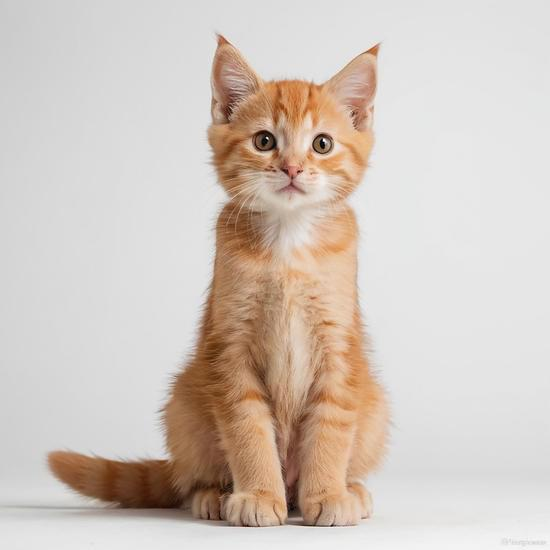

In [59]:
import base64

def analyze_image(path, model):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    prompt = """Analyze this image.

Identify:
1. Main objects
2. Environment
3. Text visible in the image
4. Possible interpretation"""
    return generate(prompt, model=model, images=[b64])

if os.path.exists(IMAGE_PATH):
    out = analyze_image(IMAGE_PATH, VISION_MODEL)
    print(out["response"], f"\n⏱ {out['wall_s']:.1f}s")
    from IPython.display import Image, display
    display(Image(IMAGE_PATH, width=400))
else:
    print(f"⚠️ Put an image named '{IMAGE_PATH}' next to this notebook, then re-run.")

In [58]:
import os
print(os.getcwd())

C:\Users\MOUADILI


**Difference between an LLM and a multimodal model?**

A classic LLM only works with text: it reads text and writes text. A multimodal model can also understand other inputs, such as images. It adds a vision encoder that turns the image into numbers the language model can use, so it can describe the image, read its text or answer questions about it.

**What additional information does the vision model receive?**

Besides the text prompt, it receives the image itself. The image is read in Python, converted to base64 text, and sent in the images field of the request. The model then turns it into vectors and processes them together with the prompt.

**Which applications could use local vision AI?**

Local vision AI is useful when images are private or when there is no Internet: reading invoices and scanned documents (OCR), detecting defects in factories, explaining diagrams or exercises in education, preparing medical images without sending patient data outside, and analyzing camera images while keeping videos on site.

**Observation**

I tested gemma3 on a photo of a kitten. It correctly identified the kitten, the white studio background, and read the small copyright text in the corner, which shows basic OCR ability. The analysis took 95.6 s on the CPU, and the image never left my computer. At the end, the model offered to "zoom in" on the image, which it cannot actually do: a small example of the model claiming abilities it does not have.

# Part 15 — Build a Local AI Web Application

In [64]:
!pip install -q flask requests
os.makedirs("local-ai-web/templates", exist_ok=True)
os.makedirs("local-ai-web/static", exist_ok=True)

In [62]:
%%writefile local-ai-web/app.py
from flask import Flask, render_template, request
import requests

app = Flask(__name__)

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "qwen3.5"


@app.route("/", methods=["GET", "POST"])
def index():
    answer = ""

    if request.method == "POST":
        question = request.form["question"]
        data = {"model": MODEL, "prompt": question, "stream": False}
        response = requests.post(OLLAMA_URL, json=data)
        answer = response.json()["response"]

    return render_template("index.html", answer=answer)


if __name__ == "__main__":
    app.run(debug=True)

Overwriting local-ai-web/app.py


In [63]:
%%writefile local-ai-web/templates/index.html
<!DOCTYPE html>
<html>
<head>
    <title>Local AI Assistant</title>
</head>
<body>

<h1>Local AI Assistant</h1>

<form method="POST">
    <textarea name="question" rows="8" cols="70" placeholder="Ask your local AI..."></textarea>
    <br><br>
    <button type="submit">Ask</button>
</form>

{% if answer %}
<h2>Response</h2>
<pre>{{ answer }}</pre>
{% endif %}

</body>
</html>

Writing local-ai-web/templates/index.html


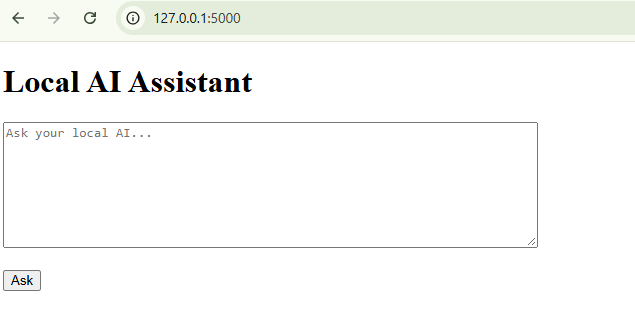

# Part 16 — Performance Benchmark

In [69]:
!pip install -q psutil

In [70]:
%%writefile benchmark.py
"""Benchmark local Ollama models on the same prompt."""
import time, requests, psutil, pandas as pd

OLLAMA = "http://localhost:11434"
PROMPT = "Write a 500-word explanation of reinforcement learning."


def unload(model):
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(2)


def loaded_info(model):
    for m in requests.get(f"{OLLAMA}/api/ps").json()["models"]:
        if m["name"].startswith(model.split(":")[0]):
            return m["size"] / 1e9, m.get("size_vram", 0) / 1e9
    return float("nan"), float("nan")


def bench(model, prompt=PROMPT, runs=1):
    rows = []
    for _ in range(runs):
        unload(model)                       # cold start, so the load time is visible
        t0 = time.perf_counter()
        r = requests.post(f"{OLLAMA}/api/generate",
                          json={"model": model, "prompt": prompt, "stream": False,
                                "think": False}, timeout=900).json()
        wall = time.perf_counter() - t0
        total_gb, vram_gb = loaded_info(model)
        rows.append({
            "Model": model,
            "Disk size (GB)": next((m["size"] / 1e9 for m in requests.get(f"{OLLAMA}/api/tags").json()["models"]
                                    if m["name"].startswith(model.split(":")[0])), float("nan")),
            "Loaded size (GB)": total_gb,
            "VRAM (GB)": vram_gb,
            "Load time (s)": r.get("load_duration", 0) / 1e9,
            "Response time (s)": wall,
            "Tokens": r.get("eval_count"),
            "Tokens/s": r["eval_count"] / (r["eval_duration"] / 1e9),
            "System RAM used (%)": psutil.virtual_memory().percent,
        })
    return pd.DataFrame(rows)


if __name__ == "__main__":
    import sys
    print(pd.concat([bench(m) for m in sys.argv[1:]]).round(2).to_string(index=False))

Overwriting benchmark.py


In [71]:
import benchmark; importlib.reload(benchmark)

bench_df = pd.concat([benchmark.bench(m) for m in (MODEL, MODEL2)], ignore_index=True)
bench_df["Quality /5"] = None   # <- fill in after reading both answers
bench_df.round(2)

,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,qwen3.5,6.55,6.19,0.0,15.19,222.18,758,3.73,88.7,None
1,gemma3,3.35,2.89,0.0,39.76,167.28,821,6.76,96.8,None


In [73]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.5 MB 8.1 MB/s eta 0:00:02
   -------------- ------------------------- 3.4/9.5 MB 9.2 MB/s eta 0:00:01
   ------------------------ --------------- 5.8/9.5 MB 9.9 MB/s eta 0:00:01
   ----------------------------------- ---- 8.4/9.5 MB 10.4 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 9.3 MB/s  0:00:01
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ----------------------------- ---------- 1.8/2.5 MB 9.1 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 8.4 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------- ----------------------------- 1.8/7.3 MB 10.0 MB/s eta 0:00:01
   --------------------- ------------------ 3.9/7.3 MB 9.8 MB/s eta 0:00:01
   --------------------------------- ------ 6.0/7.3 MB 9.6 MB/s eta 0:00:01
   ----------------------------------

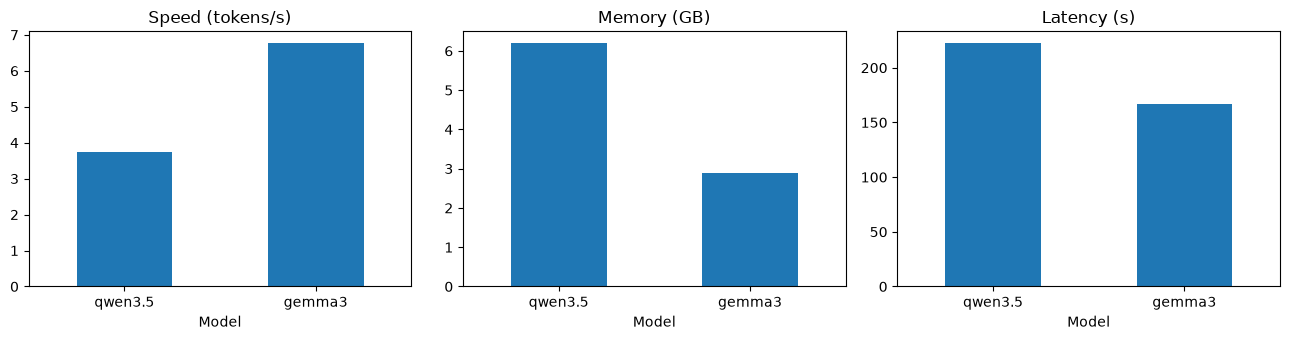

In [74]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bench_df.plot.bar(x="Model", y="Tokens/s", ax=ax[0], legend=False, title="Speed (tokens/s)", rot=0)
bench_df.plot.bar(x="Model", y="Loaded size (GB)", ax=ax[1], legend=False, title="Memory (GB)", rot=0)
bench_df.plot.bar(x="Model", y="Response time (s)", ax=ax[2], legend=False, title="Latency (s)", rot=0)
plt.tight_layout(); plt.show()

**Discussion — the model-size trade-off**

The results confirm the size trade-off. Qwen 3.5 (9B) uses 6.19 GB of memory, against 2.89 GB for Gemma 3 (4B). VRAM is 0 GB for both, so everything ran on the CPU.

Gemma 3 was about 1.8 times faster (6.76 against 3.73 tokens/s) and answered in 167 s against 222 s, even though it wrote a longer answer (821 against 758 tokens). Both speeds remain far too slow for comfortable interactive use compared with a cloud API.

Surprisingly, Gemma 3 took longer to load (39.8 s against 15.2 s) although it is smaller. Qwen 3.5 was still in memory at that moment and RAM usage reached 96.8%, so Windows had to free memory first. The state of the machine therefore matters as much as the model.

In terms of quality, the larger model was only slightly better in the previous exercises, and both made some mistakes. On this CPU-only machine with limited RAM, Gemma 3 is the best choice: faster, half the memory, and acceptable quality. This shows that a local model should be chosen from real measurements on the target machine, not from public rankings.

# Part 17 — Final Mini Project: FSTT Local AI Assistant

In [77]:
import shutil
if os.path.exists("hors_lab/systemCodetxt.txt"):
    shutil.move("hors_lab/systemCodetxt.txt", "documents/systemCodetxt.txt")
    print("Fichier remis dans Documents")

Fichier remis dans Documents


In [79]:
import shutil
base = "LocalAI_Lab"
for d in ("source/templates", "documents", "screenshots"):
    os.makedirs(f"{base}/{d}", exist_ok=True)

shutil.copy("rag.py", f"{base}/source/rag.py")
shutil.copy("benchmark.py", f"{base}/source/benchmark.py")

lab_docs = ["ai.txt", "machine_learning.txt", "reinforcement_learning.txt",
            "deep_learning.txt", "course.txt"]
for fn in lab_docs:
    shutil.copy(f"documents/{fn}", f"{base}/documents/{fn}")

print(sorted(os.listdir(f"{base}/documents")))

['$ flask db --help.docx', 'ai.txt', 'course.txt', 'deep_learning.txt', 'machine_learning.txt', 'reinforcement_learning.txt']


In [80]:
%%writefile LocalAI_Lab/source/chatbot.py
"""Console chatbot with conversation memory (uses /api/chat)."""
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3.5"


def main():
    messages = [{"role": "system", "content": "You are a helpful, concise assistant."}]
    print("Local AI Assistant — type 'exit' to stop.")
    while True:
        q = input("\nYou: ")
        if q.lower() == "exit":
            break
        messages.append({"role": "user", "content": q})
        r = requests.post(f"{OLLAMA}/api/chat",
                          json={"model": MODEL, "messages": messages, "stream": False})
        r.raise_for_status()
        reply = r.json()["message"]
        messages.append({"role": "assistant", "content": reply["content"]})
        print("\nAI:", reply["content"])


if __name__ == "__main__":
    main()

Writing LocalAI_Lab/source/chatbot.py


In [81]:
%%writefile LocalAI_Lab/source/app.py
"""FSTT Local AI Assistant — Flask + Ollama + local RAG + conversation history."""
import json, os, time
import requests
from flask import Flask, jsonify, render_template, request

import rag

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")
MODEL = os.environ.get("MODEL", "qwen3.5")
DOC_DIR = os.path.join(os.path.dirname(__file__), "..", "documents")
MAX_TURNS = 6                      # remembered user/assistant pairs

app = Flask(__name__)
retriever = rag.Retriever(rag.load_documents(DOC_DIR))
history = []                       # [{"role": ..., "content": ...}]  (single-user demo)

SYSTEM = ("You are the FSTT Local AI Assistant. Answer questions about the course using only the "
          "provided CONTEXT. If the answer is not in the context, say: \"Information not available.\" "
          "Be concise.")

# Structured response schema used for "Analyze ..." / "Quiz ..." style questions
STRUCT_SCHEMA = {
    "type": "object",
    "properties": {
        "topic": {"type": "string"},
        "summary": {"type": "string"},
        "key_points": {"type": "array", "items": {"type": "string"}},
        "difficulty": {"type": "string", "enum": ["easy", "medium", "hard"]},
    },
    "required": ["topic", "summary", "key_points", "difficulty"],
}


def call_ollama(messages, structured=False):
    payload = {"model": MODEL, "messages": messages, "stream": False, "think": False}
    if structured:
        payload["format"] = STRUCT_SCHEMA
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()


@app.route("/")
def index():
    return render_template("index.html", model=MODEL, docs=list(retriever.docs))


@app.route("/ask", methods=["POST"])
def ask():
    body = request.get_json(force=True)
    question = (body.get("question") or "").strip()
    structured = bool(body.get("structured"))
    if not question:
        return jsonify(error="Empty question"), 400

    hits, context = retriever.context(question, k=2)
    user_msg = f"CONTEXT:\n{context or '(none)'}\n\nQUESTION: {question}"
    messages = [{"role": "system", "content": SYSTEM}] + history[-2 * MAX_TURNS:] \
               + [{"role": "user", "content": user_msg}]

    t0 = time.perf_counter()
    try:
        out = call_ollama(messages, structured)
    except requests.RequestException as e:
        return jsonify(error=f"Ollama error: {e}"), 502
    elapsed = time.perf_counter() - t0

    answer = out["message"]["content"]
    # store the plain question (not the long context) to keep history small
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})

    parsed = None
    if structured:
        try:
            parsed = json.loads(answer)
        except json.JSONDecodeError:
            pass

    tokens = out.get("eval_count")
    tps = tokens / (out["eval_duration"] / 1e9) if tokens and out.get("eval_duration") else None
    return jsonify(answer=answer, structured=parsed,
                   sources=[{"doc": n, "score": round(s, 2)} for n, s in hits],
                   seconds=round(elapsed, 2), tokens=tokens,
                   tokens_per_s=round(tps, 1) if tps else None)


@app.route("/reset", methods=["POST"])
def reset():
    history.clear()
    return jsonify(ok=True)


if __name__ == "__main__":
    # Bind to localhost ONLY (see report question Q15 on security)
    app.run(host="127.0.0.1", port=int(os.environ.get("PORT", 5001)), debug=False)

Writing LocalAI_Lab/source/app.py


In [82]:
%%writefile LocalAI_Lab/source/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>FSTT Local AI Assistant</title>
<style>
  body { font-family: system-ui, sans-serif; max-width: 820px; margin: 2rem auto; padding: 0 1rem; color:#222; }
  h1 { margin-bottom: .2rem; } .sub { color:#666; font-size:.9rem; margin-bottom:1rem; }
  #chat { border:1px solid #ddd; border-radius:8px; padding:1rem; height:420px; overflow-y:auto; background:#fafafa; }
  .msg { margin:.6rem 0; padding:.6rem .8rem; border-radius:8px; white-space:pre-wrap; }
  .user { background:#e3f0ff; } .ai { background:#fff; border:1px solid #e5e5e5; }
  .meta { font-size:.75rem; color:#777; margin-top:.3rem; }
  form { display:flex; gap:.5rem; margin-top:1rem; } input[type=text] { flex:1; padding:.6rem; }
  button { padding:.6rem 1rem; cursor:pointer; } label { font-size:.85rem; }
</style>
</head>
<body>
<h1>🎓 FSTT Local AI Assistant</h1>
<div class="sub">Model: <b>{{ model }}</b> · Documents: {{ docs|join(", ") }} · Runs 100% locally</div>
<div id="chat"></div>
<form id="f">
  <input type="text" id="q" placeholder="Ask a question about the course..." autocomplete="off" autofocus>
  <button type="submit">Ask</button>
  <button type="button" id="reset">Reset</button>
</form>
<label><input type="checkbox" id="struct"> Structured response (JSON)</label>

<script>
const chat = document.getElementById("chat");
function add(cls, text, meta) {
  const d = document.createElement("div"); d.className = "msg " + cls; d.textContent = text;
  if (meta) { const m = document.createElement("div"); m.className = "meta"; m.textContent = meta; d.appendChild(m); }
  chat.appendChild(d); chat.scrollTop = chat.scrollHeight; return d;
}
document.getElementById("f").onsubmit = async (e) => {
  e.preventDefault();
  const q = document.getElementById("q"); const question = q.value.trim(); if (!question) return;
  q.value = ""; add("user", question);
  const wait = add("ai", "…thinking…");
  try {
    const r = await fetch("/ask", {method:"POST", headers:{"Content-Type":"application/json"},
      body: JSON.stringify({question, structured: document.getElementById("struct").checked})});
    const j = await r.json(); wait.remove();
    if (j.error) { add("ai", "⚠️ " + j.error); return; }
    const text = j.structured ? JSON.stringify(j.structured, null, 2) : j.answer;
    const src = j.sources.map(s => s.doc).join(", ") || "none";
    add("ai", text, `⏱ ${j.seconds}s · ${j.tokens ?? "?"} tokens · ${j.tokens_per_s ?? "?"} tok/s · sources: ${src}`);
  } catch (err) { wait.remove(); add("ai", "⚠️ " + err); }
};
document.getElementById("reset").onclick = async () => { await fetch("/reset", {method:"POST"}); chat.innerHTML = ""; };
</script>
</body>
</html>

Writing LocalAI_Lab/source/templates/index.html


In [83]:
%%writefile LocalAI_Lab/README.md
# FSTT Local AI Assistant

A fully local assistant: Flask web UI → Ollama → local LLM, with a keyword (TF-IDF) retriever over `documents/`,
conversation history, structured (JSON) answers and response-time display.

## Setup
```bash
ollama pull qwen3.5
pip install flask requests psutil pandas
```

## Run
```bash
cd source
python app.py            # http://127.0.0.1:5001
python chatbot.py        # console chatbot
python benchmark.py qwen3.5 gemma3
```
Environment variables: `MODEL`, `OLLAMA_URL`, `PORT`.

Writing LocalAI_Lab/README.md


In [84]:
import subprocess, sys, time

env = {**os.environ, "MODEL": MODEL, "PORT": "5001"}
server = subprocess.Popen([sys.executable, "app.py"], cwd="LocalAI_Lab/source", env=env,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(3)

def app_ask(q, structured=False):
    r = requests.post("http://127.0.0.1:5001/ask", json={"question": q, "structured": structured}, timeout=600)
    return r.json()

try:
    for q, s in [("What is reinforcement learning?", False),
                 ("And how is it different from supervised learning?", False),   # tests history
                 ("Summarize deep learning", True),                              # structured
                 ("What is quantum computing?", False)]:                         # not in the docs
        j = app_ask(q, s)
        print(f"Q: {q}\nA: {j.get('structured') or j.get('answer') or j}\n"
              f"   sources={j.get('sources')} · {j.get('seconds')}s · {j.get('tokens_per_s')} tok/s\n")
finally:
    pass  # keep running so you can open http://127.0.0.1:5001 — stop in the next cell

Q: What is reinforcement learning?
A: Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward, aiming to learn a policy that maximises the cumulative reward.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'reinforcement_learning.txt', 'score': 1.02}] · 35.55s · 4.6 tok/s

Q: And how is it different from supervised learning?
A: Reinforcement learning learns through interaction with an environment using rewards and penalties, whereas supervised learning uses labelled data to learn a mapping from inputs to outputs. Additionally, the provided context distinguishes reinforcement learning from unsupervised learning (which works with unlabelled data) but does not explicitly compare it to supervised learning beyond the fundamental difference of labelled vs. unlabelled data or interaction-based learning.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'machine_lear